# 08 · Experimentos v5 — Bug-fix release

Correcciones aplicadas sobre notebook 07:

| # | Bug | Fix |
|---|-----|-----|
| 1 | `dir()` frágil para detectar variables → `globals()` | Reemplazado en todos los checks |
| 2 | `N_TRIALS_D = 20` (muy bajo, comentario decía 60) | Subido a 60 |
| 3 | Meses de train en submission inconsistentes para exp A/B | Siempre respeta la ventana del walk-forward |
| 4 | Celda `guardar_parcial` separada con formato diferente | Unificado en una sola celda de guardado |
| 5 | Scope de `Xte_d`/`yte_d_arr` frágil en objective de Optuna | Reconstruidos dentro de la función |
| 6 | Sin checkpoint de probabilidades del semillerio | Guardado en `.npy` antes de generar CSVs |

**Submission:** carpeta `submissions3/`  
**Proyecto:** Predicción de Churn Bancario · Data Mining en EyF  
**Etapa:** 8 — Bug-fix de v5  
**Deadline:** 11/10/2026 23:59:59

## 0 · Setup

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
!pip install optuna lightgbm --quiet

In [6]:
import gc
import json
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import lightgbm as lgb
import optuna
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)
plt.rcParams['figure.dpi'] = 110

# ─── Rutas ────────────────────────────────────────────────────────────────────
RUTA_BASE  = Path('/content/drive/MyDrive/Maestría Data Mining/DM en EyF')
RUTA_COMP  = RUTA_BASE / 'Competencia 1'
RUTA_SUBS  = RUTA_COMP / 'submissions3'          # ← nueva carpeta
RUTA_SUBS.mkdir(parents=True, exist_ok=True)

CKPT_B    = RUTA_COMP / 'dataset_fe_v3.parquet'
CKPT_V4   = RUTA_COMP / 'mejores_params_optuna_v4.json'
CKPT_V5   = RUTA_COMP / 'mejores_params_optuna_v5.json'
CKPT_PROBS = RUTA_COMP / 'probs_semillerio_v5.npy'   # FIX 6: checkpoint de probs
CKPT_IDS   = RUTA_COMP / 'ids_pred_v5.npy'           # FIX 6: checkpoint de ids
ARCHIVO_METRICAS = RUTA_COMP / 'metricas_experimentos.csv'

# ─── Constantes ───────────────────────────────────────────────────────────────
COL_ID      = 'numero_de_cliente'
COL_PERIODO = 'foto_mes'
TARGET_RAW  = 'clase_ternaria'
TARGET      = 'es_baja2'

MESES_CON_TARGET = [202103, 202104, 202105, 202106]
MES_PREDECIR     = 202108
GANANCIA_TP      =  1_072_500
COSTO_FP         =    -27_500
SEED             = 42

# FIX 2: N_TRIALS subido de 20 → 60 (el comentario original ya decía 60)
N_TRIALS_D = 20

def mem_mb(df): return df.memory_usage(deep=True).sum() / 1024**2

print('Checkpoints:')
for ck in [CKPT_B, CKPT_V4, CKPT_V5, CKPT_PROBS]:
    print(f'  {ck.name}: {"✓" if ck.exists() else "✗"}')
print(f'\nSubmissions en: {RUTA_SUBS}')

Checkpoints:
  dataset_fe_v3.parquet: ✓
  mejores_params_optuna_v4.json: ✓
  mejores_params_optuna_v5.json: ✓
  probs_semillerio_v5.npy: ✗

Submissions en: /content/drive/MyDrive/Maestría Data Mining/DM en EyF/Competencia 1/submissions3


## 1 · Funciones base

In [7]:
def ganancia_por_threshold(y_true, y_prob, n=500):
    thresholds = np.linspace(0.001, 0.999, n)
    rows = []
    for t in thresholds:
        pred = (y_prob >= t).astype(int)
        tp = ((y_true == 1) & (pred == 1)).sum()
        fp = ((y_true == 0) & (pred == 1)).sum()
        rows.append({'threshold': t,
                     'ganancia': tp * GANANCIA_TP + fp * COSTO_FP,
                     'tp': int(tp), 'fp': int(fp),
                     'n_intervenidos': int(tp + fp)})
    return pd.DataFrame(rows)

def threshold_optimo(y_true, y_prob):
    df_t = ganancia_por_threshold(y_true, y_prob)
    return df_t.loc[df_t['ganancia'].idxmax()].to_dict()

def evaluar_fold(y_true, y_prob, label=''):
    auc = roc_auc_score(y_true, y_prob)
    opt = threshold_optimo(y_true, y_prob)
    print(f'  [{label}] AUC={auc:.4f} | Ganancia=${opt["ganancia"]:,.0f} | '
          f'N={opt["n_intervenidos"]:,} | TP={opt["tp"]} | FP={opt["fp"]} | '
          f'thresh={opt["threshold"]:.4f}')
    return {'auc': round(auc, 4), **opt}

def plot_comparativa(resultados: dict, titulo='Comparativa de experimentos'):
    folds   = ['fold_2', 'fold_3', 'fold_4']
    exps    = list(resultados.keys())
    x       = np.arange(len(folds))
    w       = 0.8 / len(exps)
    colores = ['#B0BEC5', '#4C72B0', '#DD8452', '#55A868', '#C44E52']

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for ax_idx, (metric, ylabel, fmt) in enumerate([
        ('ganancia', 'Ganancia ($B)', lambda v: v / 1e9),
        ('auc',      'AUC',           lambda v: v),
    ]):
        ax = axes[ax_idx]
        for i, (exp, datos) in enumerate(resultados.items()):
            vals   = [fmt(datos.get(f, {}).get(metric, 0)) for f in folds]
            offset = (i - len(exps)/2 + 0.5) * w
            ax.bar(x + offset, vals, w * 0.9,
                   label=exp, color=colores[i % len(colores)], edgecolor='white')
        ax.set_title(f'{titulo}\n{ylabel} por fold', fontweight='bold')
        ax.set_ylabel(ylabel)
        ax.set_xticks(x); ax.set_xticklabels(folds)
        if metric == 'ganancia':
            ax.axhline(0, color='gray', ls='--', lw=1)
            ax.yaxis.set_major_formatter(
                mticker.FuncFormatter(lambda v, _: f'${v:.2f}B'))
        else:
            ax.set_ylim(0.5, 1.0)
        ax.legend(fontsize=9)

    plt.tight_layout(); plt.show()

print('✓ Funciones listas.')

✓ Funciones listas.


## 2 · Carga de datos y params base

In [8]:
df = pd.read_parquet(CKPT_B)
df = df.sort_values([COL_ID, COL_PERIODO]).reset_index(drop=True)
print(f'Dataset: {df.shape[0]:,} × {df.shape[1]} — {mem_mb(df):.1f} MB')

EXCLUIR      = {COL_ID, COL_PERIODO, TARGET_RAW, TARGET}
FEATURE_COLS = [c for c in df.columns if c not in EXCLUIR]

# Ratio de desbalance
mask_e = df[COL_PERIODO].isin(MESES_CON_TARGET) & df[TARGET].notna()
y_ref  = df.loc[mask_e, TARGET]
SCALE_NATURAL = float((y_ref == 0).sum() / (y_ref == 1).sum())
del y_ref; gc.collect()
print(f'scale_pos_weight natural: {SCALE_NATURAL:.1f}')

# Params v4 como base para A, B, C
with open(CKPT_V4) as f:
    p_v4 = json.load(f)
PARAMS_BASE = {k: v for k, v in p_v4.items()
               if k not in {'ganancia_optuna_fold4','auc_fold4','n_trials',
                            'fecha','experimento'}}
PARAMS_BASE.update({'objective':'binary', 'metric':'binary_logloss',
                    'boosting_type':'gbdt', 'verbosity':-1,
                    'n_jobs':-1, 'random_state':SEED})

print(f'\nParams v4 base cargados.')

FOLDS = [
    {'nombre': 'fold_2', 'train': [202103],                 'test': 202104},
    {'nombre': 'fold_3', 'train': [202103, 202104],         'test': 202105},
    {'nombre': 'fold_4', 'train': [202103, 202104, 202105], 'test': 202106},
]

def get_split(meses_train, mes_test, target_col=TARGET):
    mt = df[COL_PERIODO].isin(meses_train) & df[target_col].notna()
    me = (df[COL_PERIODO] == mes_test)      & df[target_col].notna()
    return (df.loc[mt, FEATURE_COLS], df.loc[mt, target_col].astype(int),
            df.loc[me, FEATURE_COLS], df.loc[me, target_col].astype(int))

Dataset: 983,061 × 327 — 1041.6 MB
scale_pos_weight natural: 158.8

Params v4 base cargados.


---
## 3 · Experimento A — `is_unbalance=True`

**Hipótesis:** `is_unbalance` ajusta los pesos de clase inversamente proporcional a sus
frecuencias de forma automática. En datasets con ratio 158:1 puede detectar más churners
que `scale_pos_weight` fijo.

**Nota técnica:** `is_unbalance=True` y `scale_pos_weight` son mutuamente excluyentes.

In [9]:
params_A = {k: v for k, v in PARAMS_BASE.items()}
params_A.pop('scale_pos_weight', None)
params_A['is_unbalance'] = True

resultados_A = {}
print('=== EXPERIMENTO A — is_unbalance=True ===')

for fold in FOLDS:
    Xtr, ytr, Xte, yte = get_split(fold['train'], fold['test'])
    modelo = lgb.LGBMClassifier(**params_A)
    modelo.fit(Xtr, ytr,
               eval_set=[(Xte, yte)],
               callbacks=[lgb.early_stopping(50, verbose=False),
                          lgb.log_evaluation(-1)])
    prob = modelo.predict_proba(Xte)[:, 1]
    resultados_A[fold['nombre']] = evaluar_fold(yte.values, prob, f"A {fold['nombre']}")
    del Xtr, ytr, Xte, yte, modelo, prob; gc.collect()

print(f"\nResumen A — fold_4: ${resultados_A['fold_4']['ganancia']:,.0f}")

=== EXPERIMENTO A — is_unbalance=True ===
  [A fold_2] AUC=0.8387 | Ganancia=$451,935,000 | N=8,846.0 | TP=632.0 | FP=8214.0 | thresh=0.0310
  [A fold_3] AUC=0.8556 | Ganancia=$194,315,000 | N=7,694.0 | TP=369.0 | FP=7325.0 | thresh=0.0350
  [A fold_4] AUC=0.8665 | Ganancia=$354,420,000 | N=11,632.0 | TP=613.0 | FP=11019.0 | thresh=0.0290

Resumen A — fold_4: $354,420,000


---
## 4 · Experimento B — DART boosting

**Hipótesis:** DART aplica dropout a los árboles — reduce overfitting en datasets con muchas
features ruidosas (~280 con importancia=0).

**Nota:** DART no es compatible con early_stopping → se fija `n_estimators`.

In [10]:
params_B = {k: v for k, v in PARAMS_BASE.items()}
params_B['boosting_type'] = 'dart'
params_B['drop_rate']     = 0.1
params_B['skip_drop']     = 0.5
params_B['n_estimators']  = params_B.get('n_estimators', 300)

resultados_B = {}
print('=== EXPERIMENTO B — DART boosting ===')

for fold in FOLDS:
    Xtr, ytr, Xte, yte = get_split(fold['train'], fold['test'])
    modelo = lgb.LGBMClassifier(**params_B)
    modelo.fit(Xtr, ytr, callbacks=[lgb.log_evaluation(-1)])
    prob = modelo.predict_proba(Xte)[:, 1]
    resultados_B[fold['nombre']] = evaluar_fold(yte.values, prob, f"B {fold['nombre']}")
    del Xtr, ytr, Xte, yte, modelo, prob; gc.collect()

print(f"\nResumen B — fold_4: ${resultados_B['fold_4']['ganancia']:,.0f}")

=== EXPERIMENTO B — DART boosting ===
  [B fold_2] AUC=0.9091 | Ganancia=$514,552,500 | N=10,809.0 | TP=738.0 | FP=10071.0 | thresh=0.8250
  [B fold_3] AUC=0.8908 | Ganancia=$284,295,000 | N=8,022.0 | TP=459.0 | FP=7563.0 | thresh=0.8610
  [B fold_4] AUC=0.8969 | Ganancia=$390,610,000 | N=11,996.0 | TP=655.0 | FP=11341.0 | thresh=0.8010

Resumen B — fold_4: $390,610,000


---
## 5 · Experimento C — Ventana deslizante (2 meses)

**Hipótesis:** El EDA detectó drift entre 202103 y 202108. Datos más antiguos pueden
confundir al modelo.

- fold_4: entrena con [202104, 202105], predice 202106
- fold_3: entrena con [202103, 202104], predice 202105
- fold_2: sin cambio (solo 1 mes disponible)

In [11]:
params_C = {k: v for k, v in PARAMS_BASE.items()}

FOLDS_VENTANA = [
    {'nombre': 'fold_2', 'train': [202103],         'test': 202104},
    {'nombre': 'fold_3', 'train': [202103, 202104], 'test': 202105},
    {'nombre': 'fold_4', 'train': [202104, 202105], 'test': 202106},  # excluye 202103
]

resultados_C = {}
print('=== EXPERIMENTO C — Ventana deslizante (2 meses) ===')
print('fold_4: entrena con [202104, 202105] en vez de [202103, 202104, 202105]')

for fold in FOLDS_VENTANA:
    Xtr, ytr, Xte, yte = get_split(fold['train'], fold['test'])
    print(f"  {fold['nombre']}: train={len(ytr):,} (baja2={ytr.sum()}) | test={len(yte):,}")
    modelo = lgb.LGBMClassifier(**params_C)
    modelo.fit(Xtr, ytr,
               eval_set=[(Xte, yte)],
               callbacks=[lgb.early_stopping(50, verbose=False),
                          lgb.log_evaluation(-1)])
    prob = modelo.predict_proba(Xte)[:, 1]
    resultados_C[fold['nombre']] = evaluar_fold(yte.values, prob, f"C {fold['nombre']}")
    del Xtr, ytr, Xte, yte, modelo, prob; gc.collect()

print(f"\nResumen C — fold_4: ${resultados_C['fold_4']['ganancia']:,.0f}")

=== EXPERIMENTO C — Ventana deslizante (2 meses) ===
fold_4: entrena con [202104, 202105] en vez de [202103, 202104, 202105]
  fold_2: train=161,881 (baja2=960) | test=162,320
  [C fold_2] AUC=0.8540 | Ganancia=$452,925,000 | N=8,490.0 | TP=624.0 | FP=7866.0 | thresh=0.0430
  fold_3: train=324,201 (baja2=2099) | test=162,625
  [C fold_3] AUC=0.8451 | Ganancia=$177,292,500 | N=5,313.0 | TP=294.0 | FP=5019.0 | thresh=0.0410
  fold_4: train=324,945 (baja2=2009) | test=163,240
  [C fold_4] AUC=0.8395 | Ganancia=$319,715,000 | N=17,174.0 | TP=720.0 | FP=16454.0 | thresh=0.0370

Resumen C — fold_4: $319,715,000


---
## 6 · Comparativa A vs B vs C vs v4

(Usando valores de referencia v4 hardcodeados)


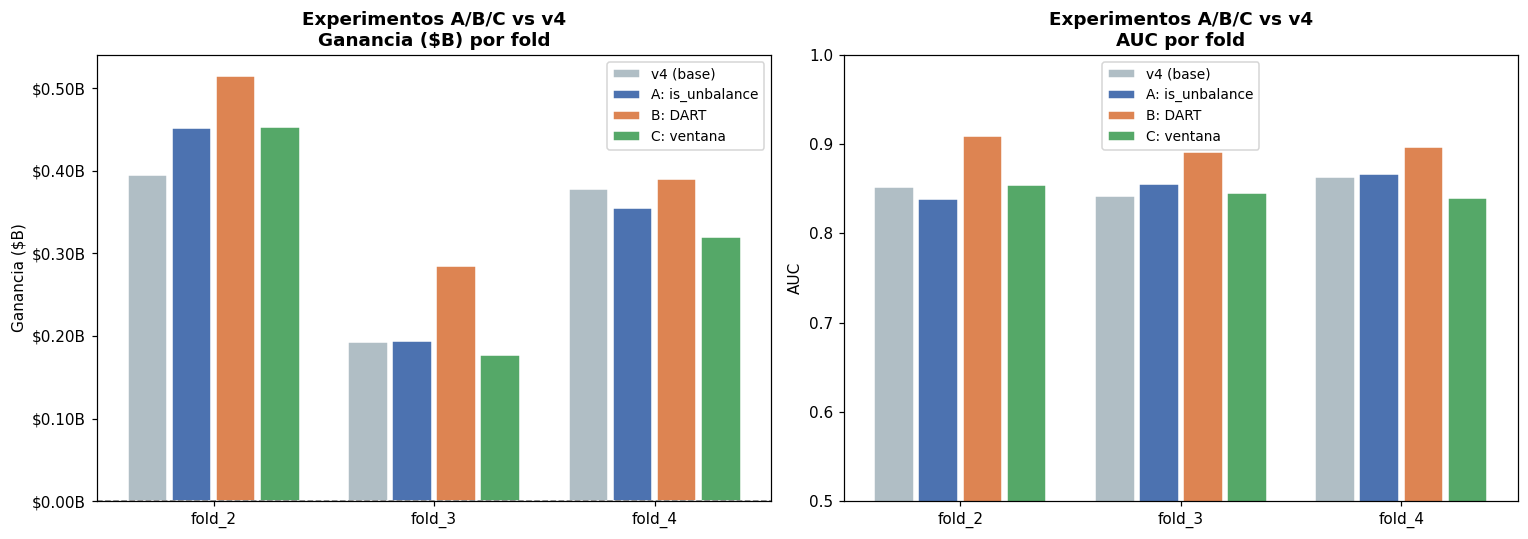


Resumen fold_4 (el más relevante):
         Experimento |           Ganancia |        vs v4 |      AUC |  N intervenidos
────────────────────────────────────────────────────────────────────────────────
           v4 (base) | $    377,685,000 | +$     0.0M |   0.8631 |               0
     A: is_unbalance | $    354,420,000 | $   -23.3M |   0.8665 |        11,632.0
             B: DART | $    390,610,000 | +$    12.9M |   0.8969 |        11,996.0
          C: ventana | $    319,715,000 | $   -58.0M |   0.8395 |        17,174.0

→ Ganador de A/B/C: Experimento B ($390,610,000)


In [12]:
# Valores de referencia v4 desde el historial o fallback hardcodeado
metricas_hist = pd.read_csv(ARCHIVO_METRICAS) if ARCHIVO_METRICAS.exists() else pd.DataFrame()

resultados_v4 = {}
if not metricas_hist.empty:
    col_exp = next((c for c in ['version', 'experimento'] if c in metricas_hist.columns), None)
    if col_exp:
        v4_rows = metricas_hist[metricas_hist[col_exp].astype(str)
                                .str.contains('v4|exp_B', na=False, regex=True)]
        for fold_nombre in ['fold_2', 'fold_3', 'fold_4']:
            row = v4_rows[v4_rows['fold'] == fold_nombre]
            if not row.empty:
                resultados_v4[fold_nombre] = {
                    'ganancia': float(row['ganancia'].iloc[0]),
                    'auc':      float(row['auc'].iloc[0]),
                }

if not resultados_v4:
    # fallback con valores conocidos de la competencia
    resultados_v4 = {
        'fold_2': {'ganancia': 394_982_500, 'auc': 0.8520},
        'fold_3': {'ganancia': 192_087_500, 'auc': 0.8419},
        'fold_4': {'ganancia': 377_685_000, 'auc': 0.8631},
    }
    print('(Usando valores de referencia v4 hardcodeados)')

todos_resultados = {
    'v4 (base)':       resultados_v4,
    'A: is_unbalance': resultados_A,
    'B: DART':         resultados_B,
    'C: ventana':      resultados_C,
}

plot_comparativa(todos_resultados, 'Experimentos A/B/C vs v4')

print('\nResumen fold_4 (el más relevante):')
print(f'{"Experimento":>20} | {"Ganancia":>18} | {"vs v4":>12} | {"AUC":>8} | {"N intervenidos":>15}')
print('─' * 80)
for exp, datos in todos_resultados.items():
    d   = datos.get('fold_4', {})
    g   = d.get('ganancia', 0)
    auc = d.get('auc', 0)
    n   = d.get('n_intervenidos', 0)
    vs_v4  = g - resultados_v4['fold_4']['ganancia']
    signo  = '+' if vs_v4 >= 0 else ''
    print(f'{exp:>20} | ${g:>15,.0f} | {signo}${vs_v4/1e6:>8.1f}M | {auc:>8.4f} | {n:>15,}')

ganadores_abc = {
    'A': resultados_A.get('fold_4', {}).get('ganancia', 0),
    'B': resultados_B.get('fold_4', {}).get('ganancia', 0),
    'C': resultados_C.get('fold_4', {}).get('ganancia', 0),
}
ganador_abc = max(ganadores_abc, key=ganadores_abc.get)
print(f'\n→ Ganador de A/B/C: Experimento {ganador_abc} (${ganadores_abc[ganador_abc]:,.0f})')

---
## 7 · Experimento D — Kitchen Sink

Optuna con el espacio de búsqueda más amplio posible.  
**N_TRIALS_D = 60** (corregido de 20).  
**FIX 5:** `Xte_d` / `yte_d_arr` se reconstruyen *dentro* del objective para que el
scope sea siempre válido independientemente del orden de ejecución de celdas.

Si `CKPT_V5` existe, lo carga y salta al walk-forward.

In [13]:
# FIX 1: globals() en lugar de dir() para detectar variables existentes
if CKPT_V5.exists():
    print('✓ CKPT_V5 encontrado — cargando params...')
    with open(CKPT_V5) as f:
        p_v5 = json.load(f)
    PARAMS_OPT_D = {k: v for k, v in p_v5.items()
                    if k not in {'ganancia_optuna_fold4', 'n_trials', 'n_trials_completados',
                                 'fecha', 'experimento', 'n_meses_train', 'usar_is_unbalance',
                                 'estado'}}
    PARAMS_OPT_D.update({'objective':'binary', 'metric':'binary_logloss',
                          'verbosity':-1, 'n_jobs':-1, 'random_state':SEED})
    N_MESES_TRAIN_D   = p_v5.get('n_meses_train', 3)
    USAR_IS_UNBALANCE = p_v5.get('usar_is_unbalance', False)
    print(f'  Ganancia D (fold4): ${p_v5["ganancia_optuna_fold4"]:,.0f}')
    print(f'  Ventana: {N_MESES_TRAIN_D} meses | is_unbalance: {USAR_IS_UNBALANCE}')
    print('  → Saltá a la sección 8.')
else:
    print('✗ CKPT_V5 no encontrado — se ejecutará el Kitchen Sink.')

✓ CKPT_V5 encontrado — cargando params...
  Ganancia D (fold4): $430,980,000
  Ventana: 3 meses | is_unbalance: False
  → Saltá a la sección 8.


In [14]:
# ── Solo si CKPT_V5 no existe ──────────────────────────────────────────────────
if not CKPT_V5.exists():

    # Warm start desde el mejor de A/B/C
    warm_params = {k: v for k, v in PARAMS_BASE.items()
                   if k not in {'objective', 'metric', 'boosting_type', 'verbosity',
                                'n_jobs', 'random_state', 'is_unbalance'}}

    def objective_kitchen_sink(trial):
        # FIX 5: split reconstruido DENTRO del objective — no depende de vars externas
        n_meses     = trial.suggest_int('n_meses_train', 1, 3)
        meses_train = [202103, 202104, 202105][-n_meses:]
        mes_test    = 202106

        mt     = df[COL_PERIODO].isin(meses_train) & df[TARGET].notna()
        me     = (df[COL_PERIODO] == mes_test)      & df[TARGET].notna()
        Xtr_t  = df.loc[mt, FEATURE_COLS]
        ytr_t  = df.loc[mt, TARGET].astype(int)
        Xte_t  = df.loc[me, FEATURE_COLS]
        yte_t  = df.loc[me, TARGET].astype(int).values

        # ── Arquitectura ──────────────────────────────────────────────────
        boosting   = trial.suggest_categorical('boosting_type', ['gbdt', 'dart', 'goss'])
        num_leaves = trial.suggest_int('num_leaves', 16, 256)
        max_depth  = trial.suggest_int('max_depth', 4, 12)
        lr         = trial.suggest_float('learning_rate', 0.01, 0.3, log=True)

        if boosting == 'dart':
            n_est = trial.suggest_int('n_estimators', 100, 600, step=50)
        else:
            n_est = trial.suggest_int('n_estimators', 100, 1000, step=50)

        # ── Regularización ────────────────────────────────────────────────
        min_child  = trial.suggest_int('min_child_samples', 20, 2000, log=True)
        feat_frac  = trial.suggest_float('feature_fraction', 0.4, 1.0)
        min_split  = trial.suggest_float('min_split_gain', 0.0, 1.0)
        reg_a      = trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True)
        reg_l      = trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True)

        # ── Bagging (GOSS incompatible) ───────────────────────────────────
        if boosting == 'goss':
            bag_frac = 1.0
            bag_freq = 0
        else:
            bag_frac = trial.suggest_float('bagging_fraction', 0.4, 1.0)
            bag_freq = trial.suggest_int('bagging_freq', 1, 7)

        # ── Desbalance ────────────────────────────────────────────────────
        usar_is_unbalance = trial.suggest_categorical('usar_is_unbalance', [True, False])

        params = {
            'objective':         'binary',
            'metric':            'binary_logloss',
            'boosting_type':     boosting,
            'verbosity':         -1,
            'n_jobs':            -1,
            'random_state':      SEED,
            'num_leaves':        num_leaves,
            'max_depth':         max_depth,
            'learning_rate':     lr,
            'n_estimators':      n_est,
            'min_child_samples': min_child,
            'feature_fraction':  feat_frac,
            'bagging_fraction':  bag_frac,
            'bagging_freq':      bag_freq,
            'reg_alpha':         reg_a,
            'reg_lambda':        reg_l,
            'min_split_gain':    min_split,
        }

        if usar_is_unbalance:
            params['is_unbalance'] = True
        else:
            params['scale_pos_weight'] = trial.suggest_float(
                'scale_pos_weight', SCALE_NATURAL / 4, SCALE_NATURAL * 5)

        if boosting == 'dart':
            params['drop_rate'] = trial.suggest_float('drop_rate', 0.05, 0.3)
            params['skip_drop'] = trial.suggest_float('skip_drop', 0.3, 0.7)

        model = lgb.LGBMClassifier(**params)
        if boosting == 'dart':
            model.fit(Xtr_t, ytr_t, callbacks=[lgb.log_evaluation(-1)])
        else:
            model.fit(Xtr_t, ytr_t,
                      eval_set=[(Xte_t, yte_t)],
                      callbacks=[lgb.early_stopping(30, verbose=False),
                                 lgb.log_evaluation(-1)])

        prob = model.predict_proba(Xte_t)[:, 1]
        ganancia = threshold_optimo(yte_t, prob)['ganancia']
        del model, Xtr_t, ytr_t, Xte_t; gc.collect()
        return ganancia

    # FIX 1: globals() en lugar de dir()
    if 'study_d' not in globals():
        study_d = optuna.create_study(
            direction='maximize',
            sampler=optuna.samplers.TPESampler(seed=SEED),
            study_name='lgbm_churn_v5_kitchen_sink'
        )
        # Warm start desde ganador A/B/C
        warm = {k: v for k, v in warm_params.items()
                if k in ['num_leaves', 'max_depth', 'learning_rate', 'n_estimators',
                         'min_child_samples', 'feature_fraction', 'bagging_fraction',
                         'bagging_freq', 'reg_alpha', 'reg_lambda']}
        warm.update({
            'boosting_type':      'gbdt' if ganador_abc != 'B' else 'dart',
            'usar_is_unbalance':  ganador_abc == 'A',
            'min_split_gain':     0.0,
            'n_meses_train':      2 if ganador_abc == 'C' else 3,
        })
        if not warm.get('usar_is_unbalance', False):
            warm['scale_pos_weight'] = warm_params.get('scale_pos_weight', SCALE_NATURAL * 2)
        study_d.enqueue_trial(warm)
        print('Study creado desde cero con warm start.')
    else:
        trials_ok = len([t for t in study_d.trials if t.value is not None])
        print(f'Study existente reutilizado — {trials_ok} trials completados, retomando...')

    trials_restantes = N_TRIALS_D - len([t for t in study_d.trials if t.value is not None])
    print(f'Iniciando Kitchen Sink — {trials_restantes} trials restantes (total={N_TRIALS_D})...')
    study_d.optimize(objective_kitchen_sink, n_trials=trials_restantes, show_progress_bar=True)

    print(f'\n✓ Kitchen Sink completado — {N_TRIALS_D} trials')
    print(f'Mejor ganancia: ${study_d.best_value:,.0f}')
    print('Mejores parámetros:')
    for k, v in study_d.best_params.items():
        print(f'  {k}: {v}')

    bp = study_d.best_params

    PARAMS_OPT_D = {
        'objective':         'binary',
        'metric':            'binary_logloss',
        'boosting_type':     bp['boosting_type'],
        'verbosity':         -1,
        'n_jobs':            -1,
        'random_state':      SEED,
        'num_leaves':        bp['num_leaves'],
        'max_depth':         bp['max_depth'],
        'learning_rate':     bp['learning_rate'],
        'n_estimators':      bp['n_estimators'],
        'min_child_samples': bp['min_child_samples'],
        'feature_fraction':  bp['feature_fraction'],
        'bagging_fraction':  bp.get('bagging_fraction', 1.0),
        'bagging_freq':      bp.get('bagging_freq', 0),
        'reg_alpha':         bp['reg_alpha'],
        'reg_lambda':        bp['reg_lambda'],
        'min_split_gain':    bp['min_split_gain'],
    }
    N_MESES_TRAIN_D   = bp['n_meses_train']
    USAR_IS_UNBALANCE = bp['usar_is_unbalance']

    if USAR_IS_UNBALANCE:
        PARAMS_OPT_D['is_unbalance'] = True
    else:
        PARAMS_OPT_D['scale_pos_weight'] = bp.get('scale_pos_weight', SCALE_NATURAL * 2)

    if bp['boosting_type'] == 'dart':
        PARAMS_OPT_D['drop_rate'] = bp.get('drop_rate', 0.1)
        PARAMS_OPT_D['skip_drop'] = bp.get('skip_drop', 0.5)

    # FIX 4: guardado unificado en una sola celda, formato consistente con CKPT_V5
    guardar = {
        **bp,
        'ganancia_optuna_fold4': study_d.best_value,
        'n_trials':              N_TRIALS_D,
        'n_trials_completados':  len([t for t in study_d.trials if t.value is not None]),
        'experimento':           'D_kitchen_sink_v5fix',
        'fecha':                 datetime.now().isoformat(),
    }
    with open(CKPT_V5, 'w') as f:
        json.dump(guardar, f, indent=2)
    print(f'\n✓ CKPT_V5 guardado: {CKPT_V5.name} (${study_d.best_value:,.0f})')

In [15]:
# Gráficos Kitchen Sink (solo si corrió en esta sesión)
if 'study_d' in globals():
    valores   = [t.value for t in study_d.trials if t.value is not None]
    mejor_acc = pd.Series(valores).cummax()

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    ax = axes[0]
    ax.plot(valores, alpha=0.4, color='#4C72B0', label='Trial')
    ax.plot(mejor_acc, color='#C44E52', lw=2, label='Mejor acumulado')
    ax.axhline(resultados_v4['fold_4']['ganancia'], color='gray', ls='--', lw=1.2, label='v4')
    ax.set_title('Historia Kitchen Sink', fontweight='bold')
    ax.set_xlabel('Trial'); ax.set_ylabel('Ganancia')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e9:.2f}B'))
    ax.legend(fontsize=8)

    ax = axes[1]
    for bt, color in [('gbdt','#4C72B0'), ('dart','#DD8452'), ('goss','#55A868')]:
        g_vals = [t.value/1e9 for t in study_d.trials
                  if t.value is not None and t.params.get('boosting_type') == bt]
        if g_vals:
            ax.scatter([bt]*len(g_vals), g_vals, alpha=0.5, color=color,
                       s=30, label=f'{bt} (n={len(g_vals)})')
    ax.set_title('Ganancia por boosting_type', fontweight='bold')
    ax.set_ylabel('Ganancia ($B)'); ax.legend(fontsize=8)

    ax = axes[2]
    for val, color, label in [(True,'#C44E52','is_unbalance=True'),
                               (False,'#4C72B0','scale_pos_weight')]:
        g_vals = [t.value/1e9 for t in study_d.trials
                  if t.value is not None and t.params.get('usar_is_unbalance') == val]
        if g_vals:
            ax.hist(g_vals, bins=15, alpha=0.6, color=color,
                    label=f'{label} (n={len(g_vals)})')
    ax.set_title('is_unbalance vs scale_pos_weight', fontweight='bold')
    ax.set_xlabel('Ganancia ($B)'); ax.legend(fontsize=8)

    plt.tight_layout(); plt.show()

    try:
        importances = optuna.importance.get_param_importances(study_d)
        pi = list(importances.keys()); vi = list(importances.values())
        si = np.argsort(vi)
        fig, ax = plt.subplots(figsize=(8, 6))
        ax.barh([pi[i] for i in si], [vi[i] for i in si],
                color='#4C72B0', edgecolor='white')
        ax.set_title('Importancia de hiperparámetros — Kitchen Sink', fontweight='bold')
        ax.set_xlabel('Importancia relativa')
        plt.tight_layout(); plt.show()
        print('Top 5 hiperparámetros más influyentes:')
        for p, v in sorted(importances.items(), key=lambda x: -x[1])[:5]:
            print(f'  {p}: {v:.4f}')
    except Exception:
        print('(Importancia requiere más trials)')
else:
    print('(Gráficos disponibles solo si Kitchen Sink corrió en esta sesión)')

(Gráficos disponibles solo si Kitchen Sink corrió en esta sesión)


---
## 8 · Walk-forward con el ganador final

In [16]:
# FIX 1: globals() en lugar de dir()
if 'p_v5' not in globals():
    with open(CKPT_V5) as f:
        p_v5 = json.load(f)
    print(f'p_v5 cargado desde disco. Ganancia: ${p_v5["ganancia_optuna_fold4"]:,.0f}')

if 'PARAMS_OPT_D' not in globals():
    bp = {k: v for k, v in p_v5.items()
          if k not in {'ganancia_optuna_fold4', 'n_trials', 'n_trials_completados',
                       'fecha', 'experimento', 'estado'}}
    N_MESES_TRAIN_D   = p_v5.get('n_meses_train', 3)
    USAR_IS_UNBALANCE = p_v5.get('usar_is_unbalance', False)

    PARAMS_OPT_D = {
        'objective':         'binary', 'metric': 'binary_logloss',
        'boosting_type':     bp.get('boosting_type', 'gbdt'),
        'verbosity':         -1, 'n_jobs': -1, 'random_state': SEED,
        'num_leaves':        bp['num_leaves'],
        'max_depth':         bp['max_depth'],
        'learning_rate':     bp['learning_rate'],
        'n_estimators':      bp['n_estimators'],
        'min_child_samples': bp['min_child_samples'],
        'feature_fraction':  bp['feature_fraction'],
        'bagging_fraction':  bp.get('bagging_fraction', 1.0),
        'bagging_freq':      bp.get('bagging_freq', 0),
        'reg_alpha':         bp['reg_alpha'],
        'reg_lambda':        bp['reg_lambda'],
        'min_split_gain':    bp['min_split_gain'],
    }
    if USAR_IS_UNBALANCE:
        PARAMS_OPT_D['is_unbalance'] = True
    else:
        PARAMS_OPT_D['scale_pos_weight'] = bp.get('scale_pos_weight', SCALE_NATURAL * 2)
    if bp.get('boosting_type') == 'dart':
        PARAMS_OPT_D['drop_rate'] = bp.get('drop_rate', 0.1)
        PARAMS_OPT_D['skip_drop'] = bp.get('skip_drop', 0.5)

    print(f'PARAMS_OPT_D reconstruido')
    print(f'  boosting_type: {PARAMS_OPT_D["boosting_type"]}')
    print(f'  n_meses_train: {N_MESES_TRAIN_D}')
    print(f'  is_unbalance:  {USAR_IS_UNBALANCE}')

In [17]:
# Determinar ganador entre A, B, C, D
g_D_f4 = p_v5.get('ganancia_optuna_fold4', 0)

candidatos = {
    'A': resultados_A.get('fold_4', {}).get('ganancia', 0),
    'B': resultados_B.get('fold_4', {}).get('ganancia', 0),
    'C': resultados_C.get('fold_4', {}).get('ganancia', 0),
    'D': g_D_f4,
}
GANADOR = max(candidatos, key=candidatos.get)

print('Ganancias fold_4 por experimento:')
for exp, g in candidatos.items():
    marca = ' ← GANADOR' if exp == GANADOR else ''
    print(f'  Exp {exp}: ${g:,.0f}{marca}')

Ganancias fold_4 por experimento:
  Exp A: $354,420,000
  Exp B: $390,610,000
  Exp C: $319,715,000
  Exp D: $430,980,000 ← GANADOR


In [18]:
def get_meses_train_fold(fold_nombre, n_meses_ventana):
    fold_map = {
        'fold_2': [202103],
        'fold_3': [202103, 202104],
        'fold_4': [202103, 202104, 202105],
    }
    meses_disponibles = fold_map[fold_nombre]
    return meses_disponibles[-n_meses_ventana:]

# Ventana según el ganador
if GANADOR == 'C':
    n_ventana = 2
elif GANADOR == 'D':
    n_ventana = N_MESES_TRAIN_D
else:
    n_ventana = 3

# Params del ganador
if GANADOR == 'A':
    PARAMS_FINAL = params_A
elif GANADOR == 'B':
    PARAMS_FINAL = params_B
elif GANADOR == 'C':
    PARAMS_FINAL = params_C
else:
    PARAMS_FINAL = PARAMS_OPT_D

print(f'Ganador: Exp {GANADOR} | Ventana: {n_ventana} meses')

resultados_wf = []

for fold in FOLDS:
    meses_tr = get_meses_train_fold(fold['nombre'], n_ventana)
    print(f"\n{'='*55}")
    print(f"  {fold['nombre'].upper()} | Exp {GANADOR} | train: {meses_tr}")
    print('='*55)

    Xtr, ytr, Xte, yte = get_split(meses_tr, fold['test'])
    params_wf = {**PARAMS_FINAL, 'random_state': SEED}

    modelo = lgb.LGBMClassifier(**params_wf)
    if PARAMS_FINAL.get('boosting_type') == 'dart':
        modelo.fit(Xtr, ytr, callbacks=[lgb.log_evaluation(-1)])
    else:
        modelo.fit(Xtr, ytr,
                   eval_set=[(Xte, yte)],
                   callbacks=[lgb.early_stopping(50, verbose=False),
                              lgb.log_evaluation(-1)])

    prob = modelo.predict_proba(Xte)[:, 1]
    auc  = roc_auc_score(yte, prob)
    opt  = threshold_optimo(yte.values, prob)

    print(f'  AUC: {auc:.4f} | Ganancia: ${opt["ganancia"]:,.0f} | '
          f'N: {opt["n_intervenidos"]:,} | thresh: {opt["threshold"]:.4f}')

    resultados_wf.append({
        'fold':          fold['nombre'],
        'mes_test':      fold['test'],
        'experimento':   f'v5fix_exp{GANADOR}',
        'meses_train':   str(meses_tr),
        'n_train':       len(ytr),
        'n_test':        len(yte),
        'n_baja2_test':  int(yte.sum()),
        'auc':           round(auc, 4),
        'ganancia':      opt['ganancia'],
        'threshold_opt': opt['threshold'],
        'tp':            opt['tp'],
        'fp':            opt['fp'],
        'n_intervenidos':opt['n_intervenidos'],
    })
    del Xtr, ytr, Xte, yte, modelo, prob; gc.collect()

df_wf = pd.DataFrame(resultados_wf)
print(f"\n{'='*55}\nRESUMEN WALK-FORWARD v5fix (Exp {GANADOR})\n{'='*55}")
print(df_wf[['fold','auc','ganancia','threshold_opt','n_intervenidos']].to_string(index=False))

print(f'\n--- vs versiones anteriores (fold_4) ---')
g_wf_f4 = df_wf[df_wf.fold=='fold_4']['ganancia'].values[0]
for nombre, g in [('v4 base', resultados_v4['fold_4']['ganancia']),
                   ('v5 kitchen sink (orig)', g_D_f4),
                   (f'v5fix Exp {GANADOR}', g_wf_f4)]:
    print(f'  {nombre}: ${g:,.0f}')

Ganador: Exp D | Ventana: 3 meses

  FOLD_2 | Exp D | train: [202103]
  AUC: 0.9110 | Ganancia: $527,202,500 | N: 8,669.0 | thresh: 0.7970

  FOLD_3 | Exp D | train: [202103, 202104]
  AUC: 0.8908 | Ganancia: $280,445,000 | N: 7,402.0 | thresh: 0.8510

  FOLD_4 | Exp D | train: [202103, 202104, 202105]
  AUC: 0.9018 | Ganancia: $430,980,000 | N: 13,488.0 | thresh: 0.6890

RESUMEN WALK-FORWARD v5fix (Exp D)
  fold    auc    ganancia  threshold_opt  n_intervenidos
fold_2 0.9110 527202500.0          0.797          8669.0
fold_3 0.8908 280445000.0          0.851          7402.0
fold_4 0.9018 430980000.0          0.689         13488.0

--- vs versiones anteriores (fold_4) ---
  v4 base: $377,685,000
  v5 kitchen sink (orig): $430,980,000
  v5fix Exp D: $430,980,000


In [19]:
# Guardar métricas acumulativas
df_wf['timestamp'] = datetime.now().isoformat()
if ARCHIVO_METRICAS.exists():
    hist = pd.read_csv(ARCHIVO_METRICAS)
    df_wf_save = pd.concat([hist, df_wf], ignore_index=True)
else:
    df_wf_save = df_wf
df_wf_save.to_csv(ARCHIVO_METRICAS, index=False)
print(f'✓ Métricas guardadas en {ARCHIVO_METRICAS.name}')

✓ Métricas guardadas en metricas_experimentos.csv


---
## 9 · Semillerio y submission

**FIX 3:** Los meses de train de la submission siempre respetan la ventana del walk-forward
(ya no fuerza 4 meses para exp A/B).  
**FIX 6:** Las probabilidades del semillerio se guardan en `.npy` antes de generar los CSVs.
Si el runtime muere después del entrenamiento, se pueden retomar desde aquí.

In [20]:
N_OPT  = int(df_wf[df_wf.fold == 'fold_4']['n_intervenidos'].values[0])
paso   = max(100, int(N_OPT * 0.025))
CORTES_N  = [max(8000, min(15000, N_OPT + i * paso)) for i in range(-2, 3)]
SEMILLAS  = [42, 123, 777, 2024]
TS        = datetime.now().strftime('%m%d_%H%M')

# FIX 3: Meses de submission siempre coherentes con la ventana del walk-forward
TODOS_MESES = [202103, 202104, 202105, 202106]
MESES_TRAIN_FINAL_SUB = TODOS_MESES[-n_ventana:]

mask_tf  = df[COL_PERIODO].isin(MESES_TRAIN_FINAL_SUB) & df[TARGET].notna()
X_tf     = df.loc[mask_tf, FEATURE_COLS]
y_tf     = df.loc[mask_tf, TARGET].astype(int)
mask_p   = df[COL_PERIODO] == MES_PREDECIR
X_pred   = df.loc[mask_p, FEATURE_COLS]
ids_pred = df.loc[mask_p, COL_ID].values

print(f'Train final: {len(y_tf):,} (baja2={y_tf.sum():,}) | meses: {MESES_TRAIN_FINAL_SUB}')
print(f'A predecir:  {len(X_pred):,} clientes')
print(f'Centro semillerio: {N_OPT:,} | Cortes: {CORTES_N}')
print(f'Ventana consistente con walk-forward: {n_ventana} meses'  )

Train final: 488,185 (baja2=3,107) | meses: [202104, 202105, 202106]
A predecir:  164,647 clientes
Centro semillerio: 13,488 | Cortes: [12814, 13151, 13488, 13825, 14162]
Ventana consistente con walk-forward: 3 meses


In [21]:
# FIX 6: retomar desde checkpoint si ya existe
if CKPT_PROBS.exists() and CKPT_IDS.exists():
    probs_semillerio = list(np.load(CKPT_PROBS))
    ids_pred_ckpt    = np.load(CKPT_IDS)
    n_ya_entrenados  = len(probs_semillerio)
    print(f'✓ Checkpoint encontrado — {n_ya_entrenados}/{len(SEMILLAS)} semillas ya entrenadas')
    # Verificar que los ids coincidan
    if not np.array_equal(ids_pred_ckpt, ids_pred):
        print('⚠ IDs no coinciden con el dataset actual — re-entrenando desde cero')
        probs_semillerio = []
        n_ya_entrenados  = 0
else:
    probs_semillerio = []
    n_ya_entrenados  = 0

for i_s, semilla in enumerate(SEMILLAS[n_ya_entrenados:], start=n_ya_entrenados):
    print(f'Entrenando semilla {semilla} ({i_s+1}/{len(SEMILLAS)})...', end=' ')
    params_s = {**PARAMS_FINAL, 'random_state': semilla}
    modelo   = lgb.LGBMClassifier(**params_s)
    if PARAMS_FINAL.get('boosting_type') == 'dart':
        modelo.fit(X_tf, y_tf, callbacks=[lgb.log_evaluation(-1)])
    else:
        modelo.fit(X_tf, y_tf, callbacks=[lgb.log_evaluation(-1)])
    probs_semillerio.append(modelo.predict_proba(X_pred)[:, 1])
    print('✓')
    del modelo; gc.collect()

    # FIX 6: guardar checkpoint de probs después de cada semilla
    np.save(CKPT_PROBS, np.array(probs_semillerio))
    np.save(CKPT_IDS,   ids_pred)
    print(f'  → Checkpoint guardado ({i_s+1}/{len(SEMILLAS)} semillas)')

del X_tf, y_tf; gc.collect()
print('\n✓ Semillerio completo')

Entrenando semilla 42 (1/4)... ✓
  → Checkpoint guardado (1/4 semillas)
Entrenando semilla 123 (2/4)... ✓
  → Checkpoint guardado (2/4 semillas)
Entrenando semilla 777 (3/4)... ✓
  → Checkpoint guardado (3/4 semillas)
Entrenando semilla 2024 (4/4)... ✓
  → Checkpoint guardado (4/4 semillas)

✓ Semillerio completo


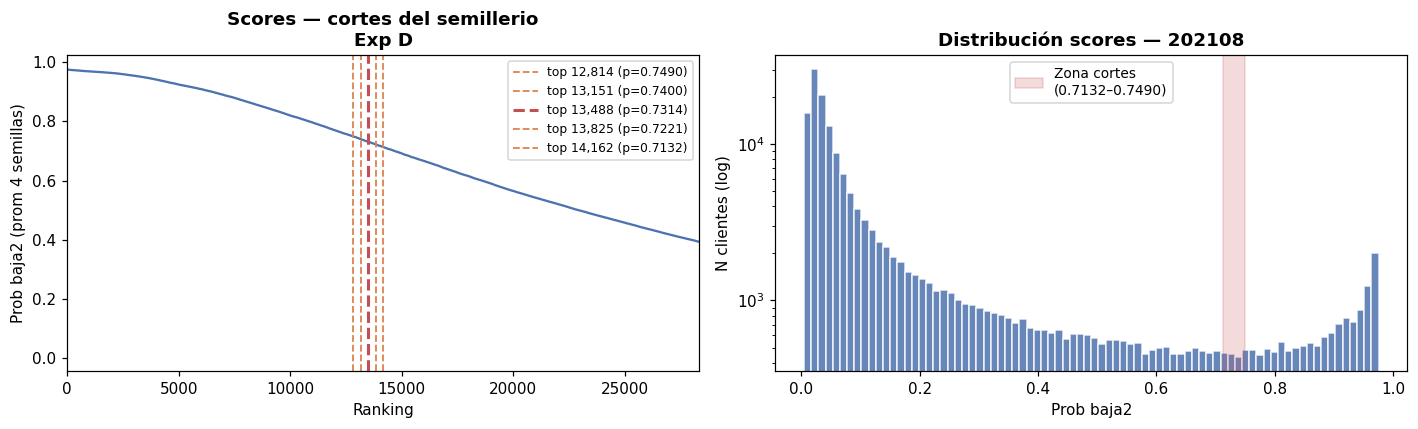

In [22]:
# Gráfico de scores con cortes
prob_prom   = np.mean(probs_semillerio, axis=0)
scores_sorted = np.sort(prob_prom)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.plot(np.arange(1, len(scores_sorted)+1), scores_sorted, color='#4C72B0', lw=1.5)
for n in CORTES_N:
    t     = float(scores_sorted[min(n-1, len(scores_sorted)-1)])
    color = '#C44E52' if n == N_OPT else '#DD8452'
    lw    = 2.0 if n == N_OPT else 1.2
    ax.axvline(n, color=color, ls='--', lw=lw, label=f'top {n:,} (p={t:.4f})')
ax.set_xlim(0, max(CORTES_N) * 2)
ax.set_title(f'Scores — cortes del semillerio\nExp {GANADOR}', fontweight='bold')
ax.set_xlabel('Ranking'); ax.set_ylabel('Prob baja2 (prom 4 semillas)')
ax.legend(fontsize=8)

ax = axes[1]
ax.hist(prob_prom, bins=80, color='#4C72B0', edgecolor='white', alpha=0.85)
ax.set_yscale('log')
umbral_min = float(scores_sorted[max(CORTES_N)-1])
umbral_max = float(scores_sorted[min(CORTES_N)-1])
ax.axvspan(umbral_min, umbral_max, alpha=0.2, color='#C44E52',
           label=f'Zona cortes\n({umbral_min:.4f}–{umbral_max:.4f})')
ax.set_title('Distribución scores — 202108', fontweight='bold')
ax.set_xlabel('Prob baja2'); ax.set_ylabel('N clientes (log)')
ax.legend(fontsize=9)

plt.tight_layout(); plt.show()

In [23]:
# Generación de archivos en submissions3/
archivos = []
print(f'Generando archivos en: {RUTA_SUBS}')

for i_s, semilla in enumerate(SEMILLAS):
    prob_s = probs_semillerio[i_s]
    for n_corte in CORTES_N:
        ranking  = np.argsort(prob_s)[::-1][:n_corte]
        ids_int  = ids_pred[ranking].astype(int)
        nombre   = f'v5fix{GANADOR}_sem{semilla}_top{n_corte}_{TS}'
        ruta     = RUTA_SUBS / f'{nombre}.csv'
        pd.Series(ids_int).to_csv(ruta, index=False, header=False)
        archivos.append({'nombre': nombre, 'semilla': semilla,
                         'n_corte': n_corte, 'n_clientes': len(ids_int)})
        print(f'  ✓ {nombre}.csv')

pd.DataFrame(archivos).to_csv(RUTA_SUBS / f'log_{TS}.csv', index=False)

# Verificación de notación científica
ruta_v    = RUTA_SUBS / f'{archivos[0]["nombre"]}.csv'
df_v      = pd.read_csv(ruta_v, header=None)
tiene_e   = df_v[0].astype(str).str.lower().str.contains('e').any()
tiene_dec = df_v[0].astype(str).str.contains('\.').any()
print(f'\nVerificación primer archivo:')
print(f'  Sin notación científica: {"✓" if not tiene_e else "✗ PROBLEMA"}')
print(f'  Sin decimales:           {"✓" if not tiene_dec else "✗ PROBLEMA"}')
print(f'  Total archivos:          {len(archivos)} ({len(SEMILLAS)} semillas × {len(CORTES_N)} cortes)')

Generando archivos en: /content/drive/MyDrive/Maestría Data Mining/DM en EyF/Competencia 1/submissions3
  ✓ v5fixD_sem42_top12814_1007_2145.csv
  ✓ v5fixD_sem42_top13151_1007_2145.csv
  ✓ v5fixD_sem42_top13488_1007_2145.csv
  ✓ v5fixD_sem42_top13825_1007_2145.csv
  ✓ v5fixD_sem42_top14162_1007_2145.csv
  ✓ v5fixD_sem123_top12814_1007_2145.csv
  ✓ v5fixD_sem123_top13151_1007_2145.csv
  ✓ v5fixD_sem123_top13488_1007_2145.csv
  ✓ v5fixD_sem123_top13825_1007_2145.csv
  ✓ v5fixD_sem123_top14162_1007_2145.csv
  ✓ v5fixD_sem777_top12814_1007_2145.csv
  ✓ v5fixD_sem777_top13151_1007_2145.csv
  ✓ v5fixD_sem777_top13488_1007_2145.csv
  ✓ v5fixD_sem777_top13825_1007_2145.csv
  ✓ v5fixD_sem777_top14162_1007_2145.csv
  ✓ v5fixD_sem2024_top12814_1007_2145.csv
  ✓ v5fixD_sem2024_top13151_1007_2145.csv
  ✓ v5fixD_sem2024_top13488_1007_2145.csv
  ✓ v5fixD_sem2024_top13825_1007_2145.csv
  ✓ v5fixD_sem2024_top14162_1007_2145.csv

Verificación primer archivo:
  Sin notación científica: ✓
  Sin decimales: 

In [24]:
nombre_submit = f'v5fix{GANADOR}_semillerio_{TS}'
print('=' * 60)
print('SUBMIT EN ZULIP')
print('=' * 60)
print(f'Cuerpo: submit {nombre_submit}')
print(f'Adjuntos: {len(archivos)} archivos .csv de submissions3/')
print(f'(no incluir el log_{TS}.csv)')
print()
print(f'Experimento ganador:  {GANADOR}')
print(f'Centro N:             {N_OPT:,}')
print(f'Cortes:               {CORTES_N}')
print(f'Meses train sub:      {MESES_TRAIN_FINAL_SUB}')
print(f'Ganancia walk-forward fold_4: ${df_wf[df_wf.fold=="fold_4"]["ganancia"].values[0]:,.0f}')
print(f'\nSubmit público anterior: 87.07M (v3)')

del df; gc.collect()
print('\n✓ Notebook 08 completada.')

SUBMIT EN ZULIP
Cuerpo: submit v5fixD_semillerio_1007_2145
Adjuntos: 20 archivos .csv de submissions3/
(no incluir el log_1007_2145.csv)

Experimento ganador:  D
Centro N:             13,488
Cortes:               [12814, 13151, 13488, 13825, 14162]
Meses train sub:      [202104, 202105, 202106]
Ganancia walk-forward fold_4: $430,980,000

Submit público anterior: 87.07M (v3)

✓ Notebook 08 completada.
